# Run AR6-fair for scenario ssp2-45, ssp1-26, ssp3-70 the same scenarios as used in the Methane pledges article on the carbon brief and of interest in Finance Sector:

https://www.carbonbrief.org/guest-post-the-global-methane-pledge-needs-to-go-further-to-help-limit-warming-to-1-5c/

I also included ssp370 in here too for interest.

In [1]:
import fair
import matplotlib.pyplot as pl
import pandas as pd
import numpy as np
import scipy.stats as st
from scipy.interpolate import interp1d
from multiprocessing import Pool
from tqdm import tqdm
import json
import pickle
#from climateforcing.twolayermodel import TwoLayerModel
from climateforcing.utils import check_and_download, mkdir_p

In [2]:
# set up plotting
pl.rcParams['figure.figsize'] = (9/2.54, 9/2.54)
pl.rcParams['font.size'] = 12
pl.rcParams['font.family'] = 'Arial'
pl.rcParams['xtick.direction'] = 'out'
pl.rcParams['ytick.direction'] = 'out'
pl.rcParams['xtick.minor.visible'] = True
pl.rcParams['ytick.major.left'] = True
pl.rcParams['ytick.major.right'] = True
pl.rcParams['ytick.minor.visible'] = True
pl.rcParams['xtick.top'] = True
pl.rcParams['ytick.right'] = True

In [3]:
# Download FaIR params set
check_and_download(
    'https://zenodo.org/record/5513022/files/fair-1.6.2-wg3-params.json', 
    '../data_input/fair_ar6/'
)

In [4]:
with open('../data_input/fair_ar6/fair-1.6.2-wg3-params.json') as f:
    config_list = json.load(f)

In [5]:
len(config_list)

2237

In [6]:
#scenarios = ['constant_forcing', 'constant_emissions', 'zero', 'scenario', 'infrastructure']
#scenarios = ['constant_emissions', 'zero', 'infrastructure', 'scenario']
# zero and constant emissions will be the easy ones, so start with these.

scenarios = ['ssp119','ssp245','ssp370']

In [7]:
# Download RCMIP emissions
check_and_download(
    'https://zenodo.org/record/4589756/files/rcmip-emissions-annual-means-v5-1-0.csv', 
    '../data_input/rcmip/'
)

In [8]:
ssp_df = pd.read_csv('../data_input/rcmip/rcmip-emissions-annual-means-v5-1-0.csv')
years = np.arange(1750, 2111)

startyear = 1750
first_scenyear = 2015
last_scenyear = 2110
first_row = int(first_scenyear-startyear)
last_row = int(last_scenyear-startyear)

species = [  # in fair 1.6, order is important
    '|CO2|MAGICC Fossil and Industrial',
    '|CO2|MAGICC AFOLU',
    '|CH4',
    '|N2O',
    '|Sulfur',
    '|CO',
    '|VOC',
    '|NOx',
    '|BC',
    '|OC',
    '|NH3',
    '|CF4',
    '|C2F6',
    '|C6F14',
    '|HFC23',
    '|HFC32',
    '|HFC4310mee',
    '|HFC125',
    '|HFC134a',
    '|HFC143a',
    '|HFC227ea',
    '|HFC245fa',
    '|SF6',
    '|CFC11',
    '|CFC12',
    '|CFC113',
    '|CFC114',
    '|CFC115',
    '|CCl4',
    '|CH3CCl3',
    '|HCFC22',
    '|HCFC141b',
    '|HCFC142b',
    '|Halon1211',
    '|Halon1202',
    '|Halon1301',
    '|Halon2402',
    '|CH3Br',
    '|CH3Cl',
]

# Assume that units coming out of aneris don't change. One day I'll do unit parsing
unit_convert = np.ones(40)
unit_convert[1] = 12/44/1000
unit_convert[2] = 12/44/1000
unit_convert[4] = 28/44/1000
unit_convert[5] = 32/64
unit_convert[8] = 14/46

data_out = {}
# 'ssp119','ssp126','ssp245','ssp370',ssp434','ssp585''

for scenario in scenarios:
    data_out[scenario] = np.ones((361, 40)) * np.nan
    data_out[scenario][:,0] = years
    print(scenario)
    years_future = [2015] + list(range(2020,2111,10))
    for i, specie in enumerate(species):
        
        data_out[scenario][:first_row,i+1] = ssp_df.loc[(ssp_df['Region']=='World')&(ssp_df['Scenario']==scenario)&(ssp_df['Variable'].str.endswith(specie)),str(startyear):'2014']*unit_convert[i+1]
        f = interp1d(years_future, ssp_df.loc[(ssp_df['Region']=='World')&(ssp_df['Scenario']==scenario)&(ssp_df['Variable'].str.endswith(specie)),'2015':'2110'].dropna(axis=1))
        data_out[scenario][first_row:(last_row+1), i+1] = f(np.arange(first_scenyear, last_scenyear+1))*unit_convert[i+1]

ssp119
ssp245
ssp370


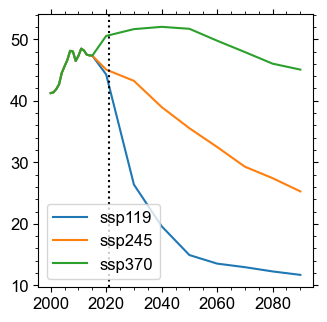

In [9]:
pl.plot(np.arange(2000, 2091), data_out['ssp119'][250:341,8], label='ssp119')
pl.plot(np.arange(2000, 2091), data_out['ssp245'][250:341,8], label='ssp245')
pl.plot(np.arange(2000, 2091), data_out['ssp370'][250:341,8], label='ssp370')
pl.axvline(2021, ls=':', color='k')
pl.legend()

# Kyoto gases

In [10]:
for scenario in scenarios:
    print('scenario ',scenario)

    #  Year FossilCO2  OtherCO2       CH4       N2O       NOx     NMVOC        CO       SOx       SOx       SOx       CF4      C2F6    HFC125   HFC134a   HFC143a  HFC227ea  HFC245fa       SF6
    #          GtC/yr    GtC/yr  MtCH4/yrMtN2O-N/yr    MtN/yr     Mt/yr   MtCO/yr    MtS/yr    MtS/yr    MtS/yr     kt/yr     kt/yr     kt/yr     kt/yr     kt/yr     kt/yr     kt/yr     kt/yr
    #co2,co2,ch4,n2o,nox,nmvoc,co,sox,sox,sox,cf4,c2f6,hfc125,hfc134a,hfc143a,hfc227ea,hfc245fa,sf6
    d =dict()
    scen_co2e =dict()
    species_col = species.copy()
    species_col.insert(0,'year')
    # Kyoto gases are CO2,CH4, N2O,CF4,C2F6,HFC125,HFC134a,HFC143a,HFC227ea,HFC245fa, SF6
    #Kyoto gases are held in columns 1,2,3,4,13,14,19,20,21,22,23,24
    # Check species and columns
    #print('CO2,CH4, N2O,CF4,C2F6,C6F14,HFC23,HFC32,HFC4310mee,HFC125,HFC134a,HFC143a,HFC227ea,HFC245fa, SF6')
    #print(species_col[1:5],species_col[12],species_col[13],
      #species_col[14],species_col[15],species_col[16],
      #species_col[17],species_col[18],species_col[19],
      #species_col[20],species_col[21],species_col[22],species_col[23])
 
 
 
    conv_ar5 ={species_col[1]: 1,species_col[2]:1,species_col[3]:28,species_col[4]:265,
           species_col[12]:6630,species_col[13]:11100,species_col[14]:7910,
           species_col[15]:12400, species_col[16]:677,species_col[17]:1650,
           species_col[18]:3170,species_col[19]:1300, species_col[20]:4800,
           species_col[21]:3350,species_col[22]:858,species_col[23]:23500}
 
    conv_ar6 ={species_col[1]: 1,species_col[2]:1,species_col[3]:27.9,species_col[4]:273,
       species_col[12]:7380,species_col[13]:12400,species_col[14]:8620,species_col[15]:14600,
       species_col[16]: 771,species_col[17]:1600,species_col[18]:3740,species_col[19]:1530,
       species_col[20]:5810,species_col[21]:3600,species_col[22]:787,species_col[23]:24300}
    conv1 = 44./12.
    #print (data_out[scenario].shape,)
    p_df = pd.DataFrame(data_out[scenario],columns=species_col)
    dat_co2e= np.ones((361, 40)) * np.nan
    dat_co2e[:,1] = p_df[species_col[1]].values[:361]*1e3*3.67
    dat_co2e[:,2] = p_df[species_col[2]].values[:361]*1e3*3.67
    dat_co2e [:,3] = p_df[species_col[3]].values[:361]*conv_ar6[species_col[3]]
    dat_co2e [:,4] = p_df[species_col[4]].values[:361]*conv_ar6[species_col[4]]*(44./28.) 
    dat_co2e [:,12] = p_df[species_col[12]].values[:361]*conv_ar6[species_col[12]]*1e-3
    dat_co2e [:,13] = p_df[species_col[13]].values[:361]*conv_ar6[species_col[13]]*1e-3
    dat_co2e [:,14] = p_df[species_col[14]].values[:361]*conv_ar6[species_col[14]]*1e-3
    dat_co2e [:,15] = p_df[species_col[15]].values[:361]*conv_ar6[species_col[15]]*1e-3
    dat_co2e [:,16] = p_df[species_col[16]].values[:361]*conv_ar6[species_col[16]]*1e-3
    dat_co2e [:,17] = p_df[species_col[17]].values[:361]*conv_ar6[species_col[17]]*1e-3
    dat_co2e [:,18] = p_df[species_col[18]].values[:361]*conv_ar6[species_col[18]]*1e-3
    dat_co2e [:,19] = p_df[species_col[19]].values[:361]*conv_ar6[species_col[19]]*1e-3
    dat_co2e [:,20] = p_df[species_col[20]].values[:361]*conv_ar6[species_col[20]]*1e-3
    dat_co2e [:,21] = p_df[species_col[21]].values[:361]*conv_ar6[species_col[21]]*1e-3
    dat_co2e [:,22] = p_df[species_col[22]].values[:361]*conv_ar6[species_col[22]]*1e-3
    dat_co2e [:,23] = p_df[species_col[23]].values[:361]*conv_ar6[species_col[23]]*1e-3
 
    
    totghg = np.nansum(dat_co2e[:,1:],axis=1)# total co2e
    edx = np.where(data_out[scenario][:,0]==2020)[0][0]
    d  = totghg[edx]*1e-3 # Convert values back into GtCO2e here
    scen_co2e[scenario] = totghg

    print(scen_co2e[scenario][280], scen_co2e[scenario][300],scen_co2e[scenario][350] )

scenario  ssp119
32301.569988574025 9227.37287965177 -8298.109282904428
scenario  ssp245
59876.99083470601 58426.37462129613 21883.2533949903
scenario  ssp370
71569.51791987584 85133.55100665713 113198.0579833807


# SSP119

In [11]:
results_out = {}

In [12]:
updated_config = []
for i, cfg in enumerate(config_list):
    updated_config.append({})
    for key, value in cfg.items():
        if isinstance(value, list):
            updated_config[i][key] = np.asarray(value)
        else:
            updated_config[i][key] = value
    updated_config[i]['emissions'] = data_out['ssp119']
    updated_config[i]['diagnostics'] = 'AR6'
    updated_config[i]["efficacy"] = np.ones(45)
    updated_config[i]["gir_carbon_cycle"] = True
    updated_config[i]["temperature_function"] = "Geoffroy"
    updated_config[i]["aerosol_forcing"] = "aerocom+ghan2"
    updated_config[i]["fixPre1850RCP"] = False
    updated_config[i]["scale"][43] = 0.6

In [13]:
def run_fair(args):
    thisC, thisF, thisT, _, thisOHU, _, thisAF = fair.forward.fair_scm(**args)
    return (thisC[:,0], thisT, np.sum(thisF[:,:43], axis=1), np.sum(thisF[:,35:41], axis=1), np.sum(thisF, axis=1))

if __name__ == '__main__':
    with Pool(28) as pool:
        result = list(tqdm(pool.imap(run_fair, updated_config), total=len(updated_config)))

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2237/2237 [01:15<00:00, 29.77it/s]


In [14]:
result_t = np.array(result).transpose(1,2,0)

In [15]:
results_out['ssp119'] = {}
c, t, f_ant, f_aer, f_tot = result_t
temp_rebase = t - t[100:151,:].mean(axis=0)
results_out['ssp119']['co2_conc'] = c
results_out['ssp119']['temp'] = temp_rebase
results_out['ssp119']['F_ant'] = f_ant
results_out['ssp119']['F_aer'] = f_aer
results_out['ssp119']['F_tot'] = f_tot

In [16]:
len(result[0])

5

In [17]:
len(updated_config)

2237

# SSP245

In [18]:
updated_config = []
for i, cfg in enumerate(config_list):
    updated_config.append({})
    for key, value in cfg.items():
        if isinstance(value, list):
            updated_config[i][key] = np.asarray(value)
        else:
            updated_config[i][key] = value
    updated_config[i]['emissions'] = data_out['ssp245']
    updated_config[i]['diagnostics'] = 'AR6'
    updated_config[i]["efficacy"] = np.ones(45)
    updated_config[i]["gir_carbon_cycle"] = True
    updated_config[i]["temperature_function"] = "Geoffroy"
    updated_config[i]["aerosol_forcing"] = "aerocom+ghan2"
    updated_config[i]["fixPre1850RCP"] = False
    updated_config[i]["scale"][43] = 0.6

In [19]:
def run_fair(args):
    thisC, thisF, thisT, _, thisOHU, _, thisAF = fair.forward.fair_scm(**args)
    return (thisC[:,0], thisT, np.sum(thisF[:,:43], axis=1), np.sum(thisF[:,35:41], axis=1), np.sum(thisF, axis=1))

if __name__ == '__main__':
    with Pool(28) as pool:
        result = list(tqdm(pool.imap(run_fair, updated_config), total=len(updated_config)))

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2237/2237 [01:15<00:00, 29.77it/s]


In [20]:
len(result[0])

5

In [21]:
len(updated_config)

2237

In [22]:
result_t = np.array(result).transpose(1,2,0)

In [23]:
results_out['ssp245'] = {}
c, t, f_ant, f_aer, f_tot = result_t
temp_rebase = t - t[100:151,:].mean(axis=0)
results_out['ssp245']['co2_conc'] = c
results_out['ssp245']['temp'] = temp_rebase
results_out['ssp245']['F_ant'] = f_ant
results_out['ssp245']['F_aer'] = f_aer
results_out['ssp245']['F_tot'] = f_tot

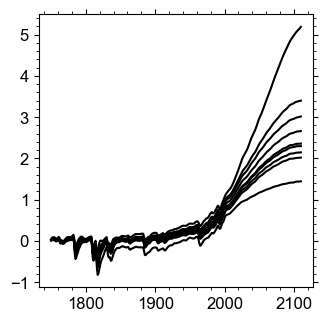

In [24]:
#temp_df = pd.read_csv('../data_input/observations/temp.csv', index_col=0)
#temp_df

for perc in [0,5,10,20,25,50,75,90,100]:
    pl.plot(np.arange(1750,2111),np.percentile(t,perc, axis=1), color='k')


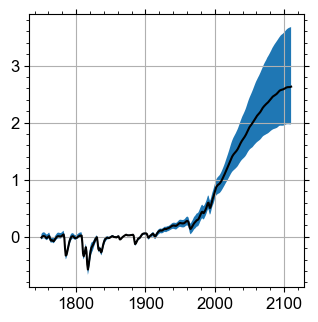

In [25]:
pl.fill_between(np.arange(1750,2111), np.percentile(results_out['ssp245']['temp'], 5, axis=1), np.percentile(results_out['ssp245']['temp'], 95, axis=1))
pl.plot(np.arange(1750,2111), np.percentile(results_out['ssp245']['temp'], 50, axis=1), color='k')
#pl.plot(temp_df.index, temp_df.temp, color='r')
#pl.ylim(0.0, 1.7)
#pl.xlim(1950, 2030)
pl.grid()

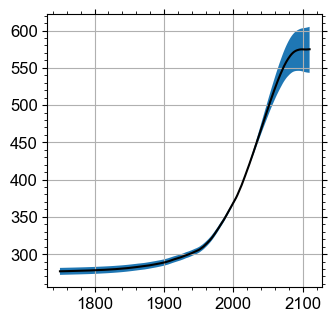

In [26]:
pl.fill_between(np.arange(1750,2111), np.percentile(results_out['ssp245']['co2_conc'], 5, axis=1), np.percentile(results_out['ssp245']['co2_conc'], 95, axis=1))
pl.plot(np.arange(1750,2111), np.percentile(results_out['ssp245']['co2_conc'], 50, axis=1), color='k')
#pl.plot(temp_df.index, temp_df.temp, color='r')
#pl.ylim(0.0, 1.7)
#pl.xlim(1950, 2030)
pl.grid()

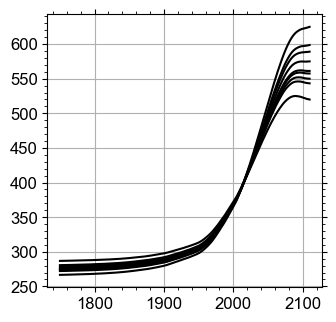

In [27]:
for perc in [0,5,10,20,25,50,75,90,100]:
    pl.plot(np.arange(1750,2111),np.percentile(c,perc, axis=1), color='k')
pl.grid()

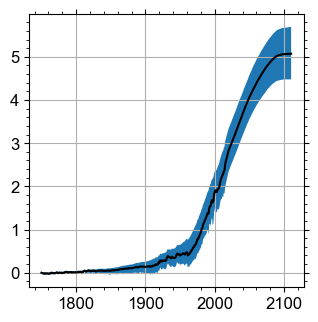

In [28]:
pl.fill_between(np.arange(1750,2111), np.percentile(f_ant, 5, axis=1), np.percentile(f_ant, 95, axis=1))
pl.plot(np.arange(1750,2111), np.percentile(f_ant, 50, axis=1), color='k')
pl.grid()

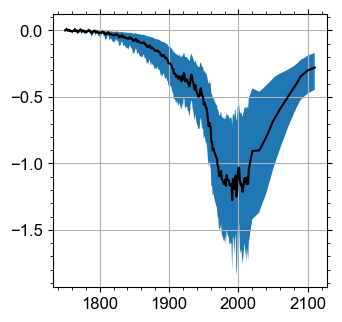

In [29]:
pl.fill_between(np.arange(1750,2111), np.percentile(f_aer, 5, axis=1), np.percentile(f_aer, 95, axis=1))
pl.plot(np.arange(1750,2111), np.percentile(f_aer, 50, axis=1), color='k')
pl.grid()

In [30]:
np.median(results_out['ssp245']['temp'], axis=1)[245:265].mean()

0.8748613261828051

In [31]:
# aerosol forcing is a little less negative than in WG3 because we use CEDS-updated not SSP historical
print(
    np.percentile(results_out['ssp245']['F_aer'], 5, axis=1)[255:265].mean(),
    np.percentile(results_out['ssp245']['F_aer'], 50, axis=1)[255:265].mean(),
    np.percentile(results_out['ssp245']['F_aer'], 95, axis=1)[255:265].mean()
)

-1.682424405229133 -1.1481288262800748 -0.5985614310021965


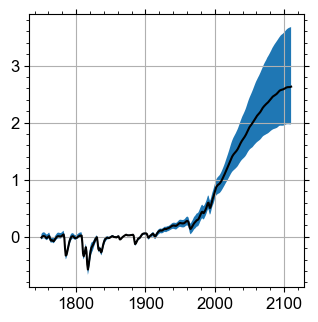

In [32]:
pl.fill_between(np.arange(1750,2111), np.percentile(results_out['ssp245']['temp'], 5, axis=1), np.percentile(results_out['ssp245']['temp'], 95, axis=1))
pl.plot(np.arange(1750,2111), np.percentile(results_out['ssp245']['temp'], 50, axis=1), color='k')
#pl.plot(temp_df.index, temp_df.temp, color='r')
#pl.ylim(0.0, 1.7)
#pl.xlim(1950, 2030)
pl.grid()

# ssp370

In [33]:
for i, cfg in enumerate(updated_config):
    updated_config[i]['emissions'] = data_out['ssp370']

In [34]:
if __name__ == '__main__':
    with Pool(28) as pool:
        result = list(tqdm(pool.imap(run_fair, updated_config), total=len(updated_config)))

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2237/2237 [01:14<00:00, 29.88it/s]


In [35]:
results_out['ssp370'] = {}
result_t = np.array(result).transpose(1,2,0)
c, t, f_ant, f_aer, f_tot = result_t
temp_rebase = t - t[100:151,:].mean(axis=0)
results_out['ssp370']['co2_conc'] = c
results_out['ssp370']['temp'] = temp_rebase
results_out['ssp370']['F_ant'] = f_ant
results_out['ssp370']['F_aer'] = f_aer
results_out['ssp370']['F_tot'] = f_tot

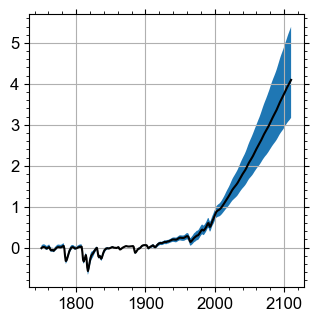

In [36]:
pl.fill_between(np.arange(1750,2111), np.percentile(results_out['ssp370']['temp'], 5, axis=1), np.percentile(results_out['ssp370']['temp'], 95, axis=1))
pl.plot(np.arange(1750,2111), np.percentile(results_out['ssp370']['temp'], 50, axis=1), color='k')
#pl.plot(temp_df.index, temp_df.temp, color='r')
pl.grid()

# All on the same plot!

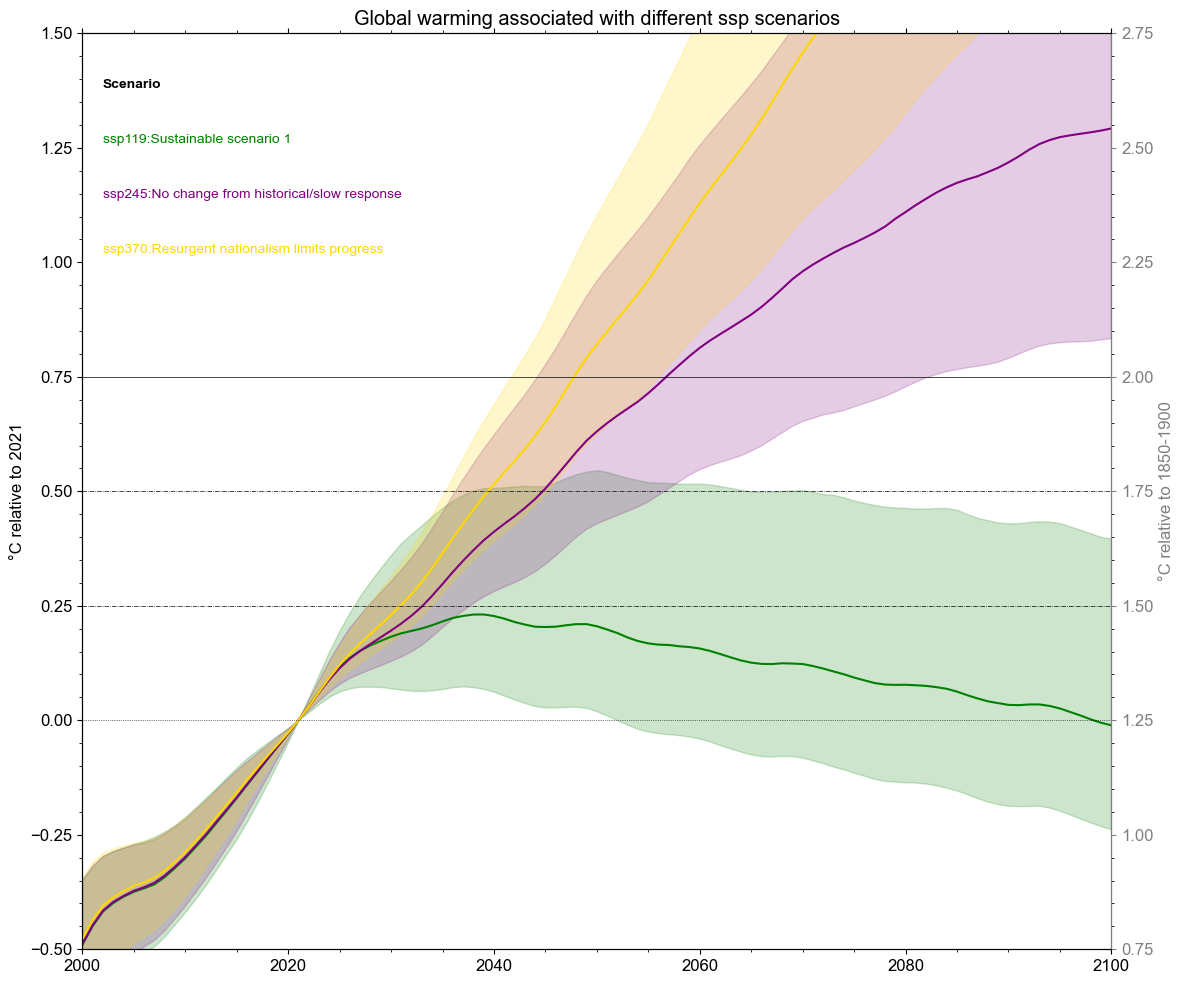

In [37]:
#scenarios = ['zero', 'constant_forcing', 'constant_emissions', 'infrastructure', 'scenario']
scenarios = ['ssp119',  'ssp126', 'ssp245', 'ssp370', 'ssp434', 'ssp585']
colors = {
    'ssp119' : 'green',
    'ssp126' : 'blue',
    'ssp245' : 'purple',
    'ssp370' : 'gold',
    'ssp434' : 'orange',
    'ssp585' : 'red'
    }

labels = {
    'ssp119' : 'ssp119:Sustainable scenario 1',
    'ssp126' : 'ssp126:Sustainable scenario 2',
    'ssp245' : 'ssp245:No change from historical/slow response',
    'ssp370' : 'ssp370:Resurgent nationalism limits progress',
    'ssp434' : 'ssp434:Uneven and slow response',
    'ssp585' : 'ssp585:Fossil-Fueled Development'
}

fig, ax = pl.subplots(figsize=(12, 10))

ax.text(0.02, 0.94, 'Scenario', fontweight='bold', fontsize=10, transform=ax.transAxes)
for i, scenario in enumerate(['ssp119','ssp245','ssp370']):
    if scenario in ['ssp119','ssp245', 'ssp370']:
        ax.fill_between(np.arange(2000,2101), np.percentile(results_out[scenario]['temp'][250:351,:] - results_out[scenario]['temp'][271,:], 5, axis=1), np.percentile(results_out[scenario]['temp'][250:351,:] - results_out[scenario]['temp'][271,:], 95, axis=1), color=colors[scenario], alpha=0.2)
    ax.plot(np.arange(2000, 2101), np.median(results_out[scenario]['temp'][250:351,:] - results_out[scenario]['temp'][271,:], axis=1), color=colors[scenario], label=labels[scenario])
    ax.text(0.02, 0.88-0.06*i, labels[scenario], color=colors[scenario], transform=ax.transAxes, fontsize=10)
#ax.legend(fontsize=10);
ax.set_ylabel('°C relative to 2021');
ax.set_title('Global warming associated with different ssp scenarios');
ax.set_xlim(2000, 2100)
ax.set_ylim(-0.5, 1.5)

from matplotlib import ticker

ax1 = ax.twinx()
positions = np.arange(0.75, 2.76, 0.25)

ax1.yaxis.set_major_locator(ticker.FixedLocator(positions))

ax1.set_ylim(0.75,2.75)
ax1.spines['right'].set_color('gray')
ax1.tick_params(axis='y', colors='gray')
ax1.set_ylabel('°C relative to 1850-1900', color='gray')


ax.axhline(0, ls=':', color='k', lw=0.5)
ax1.axhline(1.5, ls='-.', color='k', lw=0.5)
ax1.axhline(1.75, ls='-.', color='k', lw=0.5)
ax1.axhline(2.0, ls='-', color='k', lw=0.5)
fig.tight_layout()
pl.savefig('../plots/rcmip_119_245_370_scenarios_temp.png', dpi=500, transparent=False)

# All on the same plot CO2 conc!

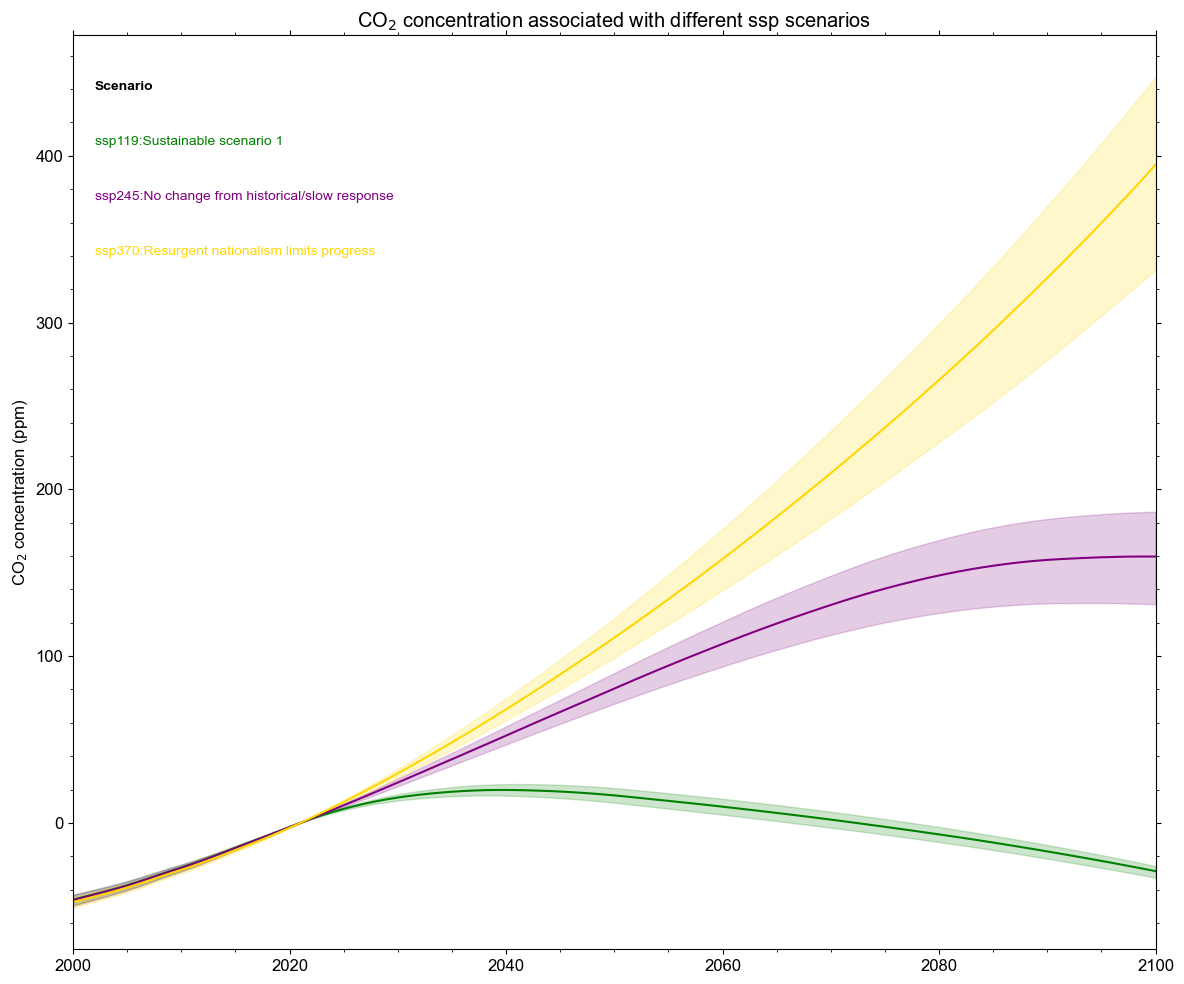

In [38]:
fig, ax = pl.subplots(figsize=(12, 10))

ax.text(0.02, 0.94, 'Scenario', fontweight='bold', fontsize=10, transform=ax.transAxes)
for i, scenario in enumerate(['ssp119','ssp245', 'ssp370']):
    #possible scenarios ['ssp119', 'ssp126', 'ssp245', 'ssp370','ssp434','ssp585']:
    ax.fill_between(np.arange(2000,2101), np.percentile(results_out[scenario]['co2_conc'][250:351,:] - results_out[scenario]['co2_conc'][271,:], 5, axis=1), np.percentile(results_out[scenario]['co2_conc'][250:351,:] - results_out[scenario]['co2_conc'][271,:], 95, axis=1), color=colors[scenario], alpha=0.2)
    ax.plot(np.arange(2000, 2101), np.median(results_out[scenario]['co2_conc'][250:351,:] - results_out[scenario]['co2_conc'][271,:], axis=1), color=colors[scenario], label=labels[scenario])
    ax.text(0.02, 0.88-0.06*i, labels[scenario], color=colors[scenario], transform=ax.transAxes, fontsize=10)
#ax.legend(fontsize=10);
ax.set_ylabel(r'CO${_2}$ concentration (ppm)');
ax.set_title(r'CO${_2}$ concentration associated with different ssp scenarios');
ax.set_xlim(2000, 2100)
#ax.set_ylim(-0.5, 1.5)

from matplotlib import ticker


ax1.yaxis.set_major_locator(ticker.FixedLocator(positions))

ax1.spines['right'].set_color('gray')
ax1.tick_params(axis='y', colors='gray')

fig.tight_layout()
pl.savefig('../plots/rcmip_119_245_370_scenarios_CO2conc.png', dpi=500, transparent=False)

# All on the same plot ERF!

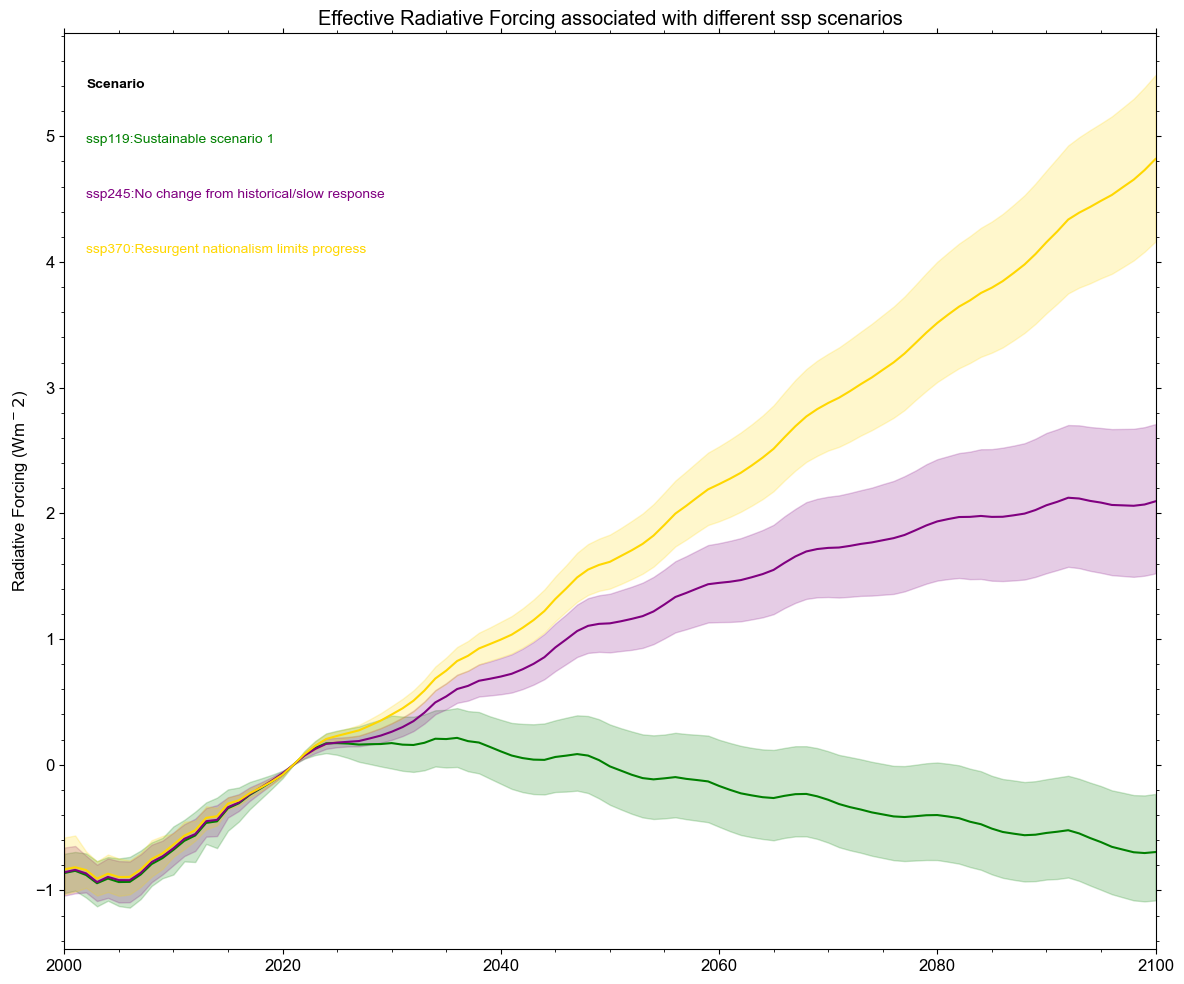

In [39]:
fig, ax = pl.subplots(figsize=(12, 10))

ax.text(0.02, 0.94, 'Scenario', fontweight='bold', fontsize=10, transform=ax.transAxes)
for i, scenario in enumerate(['ssp119','ssp245', 'ssp370']):
    #if scenario in ['ssp119', 'ssp245', 'ssp434']:
    #'ssp119', 'ssp126', 'ssp245', 'ssp370','ssp434','ssp585'
    ax.fill_between(np.arange(2000,2101), np.percentile(results_out[scenario]['F_tot'][250:351,:] - results_out[scenario]['F_tot'][271,:], 5, axis=1), np.percentile(results_out[scenario]['F_tot'][250:351,:] - results_out[scenario]['F_tot'][271,:], 95, axis=1), color=colors[scenario], alpha=0.2)
    ax.plot(np.arange(2000, 2101), np.median(results_out[scenario]['F_tot'][250:351,:] - results_out[scenario]['F_tot'][271,:], axis=1), color=colors[scenario], label=labels[scenario])
    ax.text(0.02, 0.88-0.06*i, labels[scenario], color=colors[scenario], transform=ax.transAxes, fontsize=10)
#ax.legend(fontsize=10);
ax.set_ylabel(r'Radiative Forcing (Wm${^-2}$)');
ax.set_title('Effective Radiative Forcing associated with different ssp scenarios');
ax.set_xlim(2000, 2100)
#ax.set_ylim(-0.5, 1.5)

from matplotlib import ticker


ax1.yaxis.set_major_locator(ticker.FixedLocator(positions))

ax1.spines['right'].set_color('gray')
ax1.tick_params(axis='y', colors='gray')

fig.tight_layout()
pl.savefig('../plots/rcmip_119_245_370_scenarios_erf.png', dpi=500, transparent=False)

In [40]:
for i, scenario in enumerate(['ssp119', 'ssp245', 'ssp370']):
    print('scenario ',scenario)
    print('median', np.median(results_out[scenario]['temp'][280,:]), np.median(results_out[scenario]['temp'][300,:]), np.median(results_out[scenario]['temp'][350,:]))
    print('50th percentile', np.percentile(results_out[scenario]['temp'][:361,:], 50, axis=1)[280], np.percentile(results_out[scenario]['temp'][:361,:], 50, axis=1)[300], np.percentile(results_out[scenario]['temp'][:361,:], 50, axis=1)[350])
    print('5th percentile', np.percentile(results_out[scenario]['temp'][:361,:], 5, axis=1)[280], np.percentile(results_out[scenario]['temp'][:361,:], 5, axis=1)[300], np.percentile(results_out[scenario]['temp'][:361,:], 5, axis=1)[350])
    print('95th percentile', np.percentile(results_out[scenario]['temp'][:361:], 95, axis=1)[280], np.percentile(results_out[scenario]['temp'][:361:], 95, axis=1)[300],np.percentile(results_out[scenario]['temp'][:361,:], 95, axis=1)[350])


scenario  ssp119
median 1.473364899845218 1.4977317851053664 1.2738406906291506
50th percentile 1.473364899845218 1.4977317851053664 1.2738406906291506
5th percentile 1.1609361671260714 1.1430394522305762 0.9380509084906088
95th percentile 1.864852438069191 2.017625674069071 1.8338520844408726
scenario  ssp245
median 1.4864436345463854 1.921447157761674 2.5921952197629663
50th percentile 1.4864436345463854 1.921447157761674 2.5921952197629663
5th percentile 1.196935228379801 1.525109937594784 1.951333433894645
95th percentile 1.8083201226523349 2.434728383042127 3.5822854028486435
scenario  ssp370
median 1.513037458040331 2.0957241808293094 3.7570217017668552
50th percentile 1.513037458040331 2.0957241808293094 3.7570217017668552
5th percentile 1.2225854598094592 1.690053046060315 2.9235129844407295
95th percentile 1.8106547316129287 2.583036845463631 4.908106818828452
